# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      str    
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), str(1)
memory usage: 260.0 bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     4000 non-null   int64
 1   first_name  4000 non-null   str  
 2   last_name   4000 non-null   str  
 3   age         4000 non-null   int64
 4   city        3531 non-null   str  
 5   reg_date    4000 non-null   str  
 6   plan        4000 non-null   str  
 7   churn_date  466 non-null    str  
dtypes: int64(2), str(6)
memory usage: 250.1 KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  str    
 3   date      39950 non-null  str    
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 1.8 MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print()
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print()
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico:**

*users*
- `city`: 469 nulos (11.7%). Está en el rango de 5–30%, así que se investiga: no hay forma confiable de deducir la ciudad, por lo que **se dejan como nulos**. Más adelante se les suman los 96 registros con `"?"`.
- `churn_date`: 3,534 nulos (88.4%). Aunque supera el 80%, **no se elimina ni se imputa**: el nulo significa que el cliente no se ha dado de baja, así que el dato es informativo. No se usa en este análisis porque su formato está dañado (ver paso 2.3).
- Las demás columnas no tienen nulos.

*usage*
- `date`: 50 nulos (0.1%). Es menos del 5% y la fecha no se necesita para contar el uso por usuario, así que **se dejan como nulos**.
- `duration`: 22,076 nulos (55.2%) y `length`: 17,896 nulos (44.7%). Son nulos esperados: la duración solo aplica a las llamadas y la longitud solo a los mensajes. **No se imputan**; en el paso 3.2 se verifica que dependen de `type`.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
print("Registros con age = -999:", (users['age'] == -999).sum())
print("Edad mínima y máxima sin contar -999:",
      users.loc[users['age'] != -999, 'age'].min(), users.loc[users['age'] != -999, 'age'].max())
users[['user_id', 'age']].describe()

Registros con age = -999: 55
Edad mínima y máxima sin contar -999: 18 79


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` va de 10000 a 13999 y tiene 4,000 valores, uno por usuario: es un identificador sin problemas.
- La columna `age` tiene un mínimo de **-999**, una edad imposible que funciona como sentinel y aparece en 55 registros. Por eso la desviación estándar (123) es mucho mayor de lo esperado. Sin ese valor, las edades van de 18 a 79 años.

In [13]:
# explorar columnas numéricas de usage
print(usage[['id', 'user_id', 'duration', 'length']].describe())

# valores que llaman la atención en duration y length
print("\nRegistros con duration = 120, por tipo:")
print(usage.loc[usage['duration'] == 120, 'type'].value_counts())
print("\nRegistros con length = 1490, por tipo:")
print(usage.loc[usage['length'] == 1490, 'type'].value_counts())
print("\nDuración máxima sin contar 120:", usage.loc[usage['duration'] != 120, 'duration'].max())
print("Longitud máxima sin contar 1490:", usage.loc[usage['length'] != 1490, 'length'].max())
print("Llamadas con duración 0:", (usage['duration'] == 0).sum())
print("Mensajes con longitud 0:", (usage['length'] == 0).sum())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000

Registros con duration = 120, por tipo:
type
text    16
call    14
Name: count, dtype: int64

Registros con length = 1490, por tipo:
type
text    18
call    12
Name: count, dtype: int64

Duración máxima sin contar 120: 46.98
Longitud máxima sin contar 1490: 125.0
Llamadas con duración 0: 15
Mensajes con longitud 0: 133


- Las columnas `id` y `user_id` no tienen problemas: `id` va de 1 a 40,000 sin repetirse, y `user_id` está en el mismo rango que en `users` (10000 a 13999).
- Las columnas `duration` y `length` tienen sentinels: hay **30 registros con duración de exactamente 120 minutos** y **30 con longitud de exactamente 1490 caracteres**. Están muy por encima de los valores reales (sin ellos, la llamada más larga dura 46.98 minutos y el mensaje más largo tiene 125 caracteres) y además aparecen en registros del tipo equivocado: 16 mensajes tienen duración de 120 y 12 llamadas tienen longitud de 1490.
- También hay 15 llamadas con duración 0 y 133 mensajes con longitud 0. Son posibles (llamadas no contestadas o mensajes vacíos), así que se conservan.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(users[col].value_counts(dropna=False))
    print()

city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: count, dtype: int64

plan
Basico     2595
Premium    1405
Name: count, dtype: int64



- La columna `city` tiene 6 ciudades: Bogotá (808), CDMX (730), Medellín (616), GDL (450), Cali (424) y MTY (407). Además tiene **96 registros con `"?"`**, un sentinel que significa ciudad desconocida, y 469 nulos.
- La columna `plan` solo tiene los dos planes válidos: Basico (2,595 usuarios) y Premium (1,405).

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

type
text    22092
call    17908
Name: count, dtype: int64

- La columna `type` solo tiene dos valores válidos: `text` (22,092 mensajes) y `call` (17,908 llamadas).

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

**Diagnóstico:**
- `age`: 55 registros con -999 (1.4% de los usuarios). **Acción:** reemplazarlos por la mediana de las edades válidas, porque son pocos y la mediana no se ve afectada por valores extremos.
- `city`: 96 registros con `"?"` (2.4%). **Acción:** convertirlos en nulos (`pd.NA`), porque no se puede saber la ciudad real.
- `duration`: 30 registros con 120, y `length`: 30 registros con 1490. **Acción:** convertirlos en nulos, porque no son mediciones reales; si se quedan, inflan los minutos de los usuarios afectados.
- `duration` = 0 y `length` = 0: se conservan, porque pueden ser llamadas no contestadas o mensajes vacíos.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# churn_date también es una fecha, pero viene como texto en notación científica
users['churn_date'].dropna().head()

32    1,71832E+18
38     1,7261E+18
42    1,72169E+18
44     1,7312E+18
47    1,72843E+18
Name: churn_date, dtype: str

In [19]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

reg_date
2022    1314
2023    1316
2024    1330
2026      40
Name: count, dtype: int64

En `reg_date`, los registros se reparten casi por igual entre 2022 (1,314), 2023 (1,316) y 2024 (1,330), pero hay **40 registros de 2026**, un año que todavía no había ocurrido cuando se guardaron los datos (hasta 2024). Son fechas imposibles. Todas las fechas se pudieron convertir.

In [20]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())

# rango de fechas registradas
print()
print("Fecha mínima:", usage['date'].min())
print("Fecha máxima:", usage['date'].max())

date
2024.0    39950
NaN          50
Name: count, dtype: int64

Fecha mínima: 2024-01-01 00:00:00
Fecha máxima: 2024-06-30 00:00:00


En `date`, todos los registros válidos son de 2024 (39,950) y 50 quedaron vacíos (`NaT`). Las fechas van del 1 de enero al 30 de junio de 2024, es decir, el uso registrado cubre **el primer semestre de 2024**.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

**Diagnóstico:**
- `reg_date`: hay 40 fechas de 2026 (1.0% de los usuarios), un año sin transcurrir. No hay años muy viejos: el más antiguo es 2022. **Acción:** marcarlas como nulas, porque no se puede saber la fecha real de registro.
- `date` (usage): no hay años imposibles; todo es de 2024. Las 50 fechas vacías (0.1%) se dejan como nulas, porque no afectan el conteo de uso por usuario.
- `churn_date`: también es una fecha, pero viene como texto en notación científica (por ejemplo, `1,71832E+18`). Se perdió precisión al guardarla, así que no se puede convertir de forma confiable. **Acción:** no usarla en este análisis y pedir el dato original.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
# la mediana se calcula sin el sentinel, para que -999 no la afecte
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
print("Mediana usada:", age_mediana)
users['age'].describe()

Mediana usada: 48.0


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

city
Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: count, dtype: int64

In [23]:
# Marcar fechas futuras como NA para reg_date
# en columnas de fecha, el valor nulo es pd.NaT (el equivalente de pd.NA para fechas)
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

reg_date
2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: count, dtype: int64

Además de lo que pide la consigna, se corrigen los sentinels de `usage` encontrados en el paso 2.2: los valores 120 en `duration` y 1490 en `length` se convierten en nulos (`NaN`), porque no son mediciones reales.

In [24]:
# Reemplazar los sentinels de usage por NaN
usage['duration'] = usage['duration'].replace(120, np.nan)
usage['length'] = usage['length'].replace(1490, np.nan)

# Verificar cambios
usage[['duration', 'length']].describe()

,duration,length
count,17894.000000,22074.000000
mean,5.009774,50.173235
std,4.976793,19.884646
min,0.000000,0.000000
25%,1.430000,37.000000
50%,3.490000,50.000000
75%,6.950000,64.000000
max,46.980000,125.000000


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [25]:
# Verificación MAR en usage (Missing At Random) para duration
# proporción de nulos en duration según el tipo de registro
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000782
text    1.000000
Name: duration, dtype: float64

In [26]:
# Verificación MAR en usage (Missing At Random) para length
# proporción de nulos en length según el tipo de registro
usage['length'].isna().groupby(usage['type']).mean()

type
call    1.000000
text    0.000815
Name: length, dtype: float64

**Diagnóstico de nulos en `duration` y `length`:** los nulos dependen por completo de `type`. `duration` está vacía en el 100% de los mensajes y solo en el 0.08% de las llamadas (las 14 llamadas cuyo sentinel de 120 se convirtió en nulo). Con `length` pasa al revés: está vacía en el 100% de las llamadas y solo en el 0.08% de los mensajes (los 18 mensajes con el sentinel de 1490). Por eso son **MAR**: la falta del dato se explica por otra columna observada, `type`. **Se dejan como nulos**, porque un mensaje no tiene duración y una llamada no tiene longitud; imputarlos inventaría información.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [27]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',     # total de mensajes
    'is_call': 'sum',     # total de llamadas
    'duration': 'sum'     # total de minutos de llamada
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Combinar la tabla agregada con el dataset de usuarios
# left join: se conservan todos los usuarios, aunque no tengan uso registrado
user_profile = users.merge(usage_agg, on='user_id', how='left')

# un usuario sin registros de uso queda con NaN: su uso real es 0
columnas_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print("Usuarios sin uso registrado:", user_profile['cant_mensajes'].isna().sum())
user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)

user_profile.head(5)

Usuarios sin uso registrado: 1


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [30]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,22.411225
std,17.689919,2.359738,2.145139,15.053351
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.080000
50%,48.000000,5.000000,4.000000,19.670000
75%,63.000000,7.000000,6.000000,30.992500
max,79.000000,17.000000,15.000000,105.540000


In [31]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

plan
Basico     64.875
Premium    35.125
Name: proportion, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

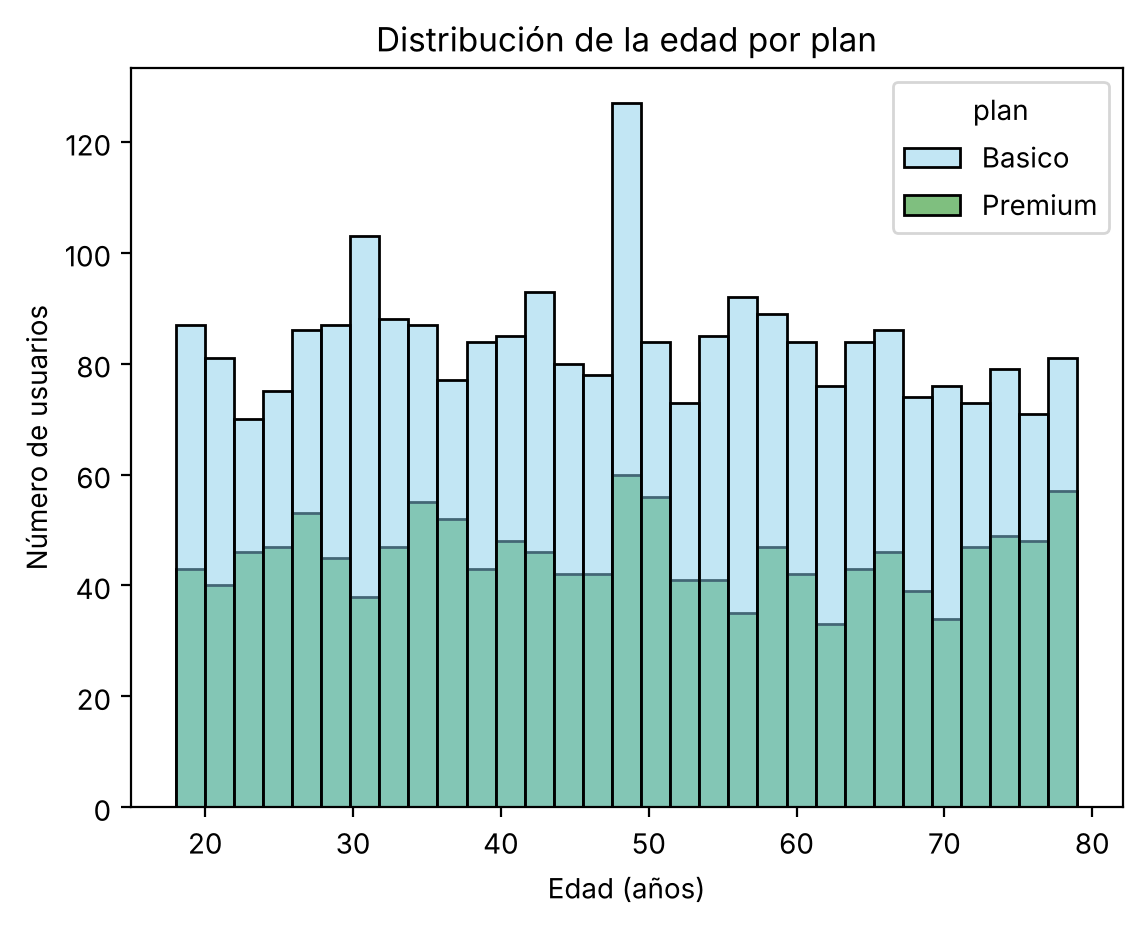

In [32]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], bins=31)
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights:
- Distribución **aproximadamente uniforme**: hay una cantidad parecida de usuarios en todas las edades, de 18 a 79 años, sin sesgo claro. El pico alrededor de los 48 años corresponde a los 55 registros con -999 que se reemplazaron por la mediana.
- Basico y Premium tienen la misma forma; las barras de Basico son más altas solo porque ese plan tiene más usuarios (65% contra 35%). No hay un rango de edad que prefiera un plan sobre el otro.

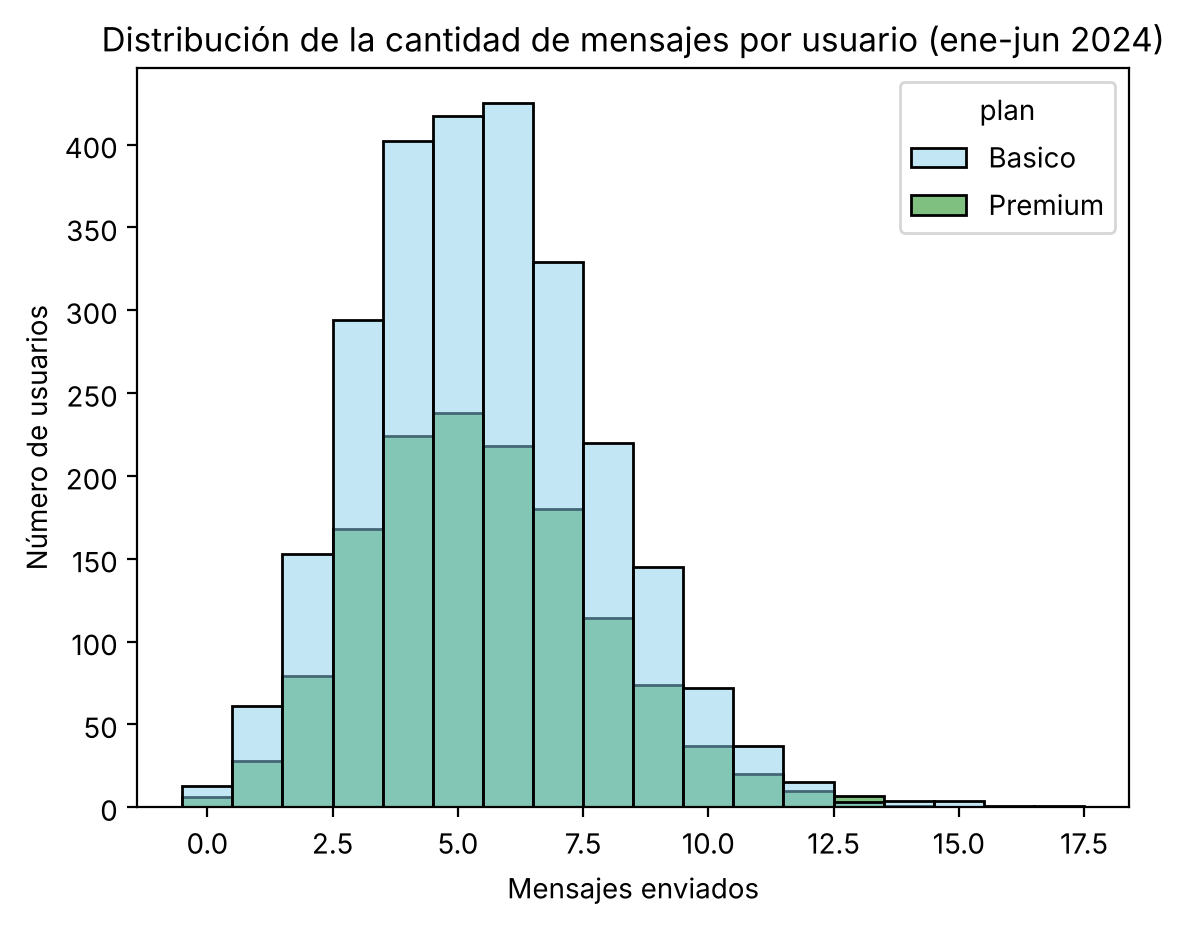

In [33]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de la cantidad de mensajes por usuario (ene-jun 2024)')
plt.xlabel('Mensajes enviados')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights:
- Distribución **casi simétrica**, con una ligera cola a la derecha: la mitad de los usuarios envió entre 4 y 7 mensajes en el semestre, con un centro en 5. Pocos superan los 12 mensajes, y el máximo es 17.
- Los usuarios Basico y Premium envían prácticamente la misma cantidad de mensajes (5.5 en promedio, ver la sección 6.4): no existe un patrón por plan.

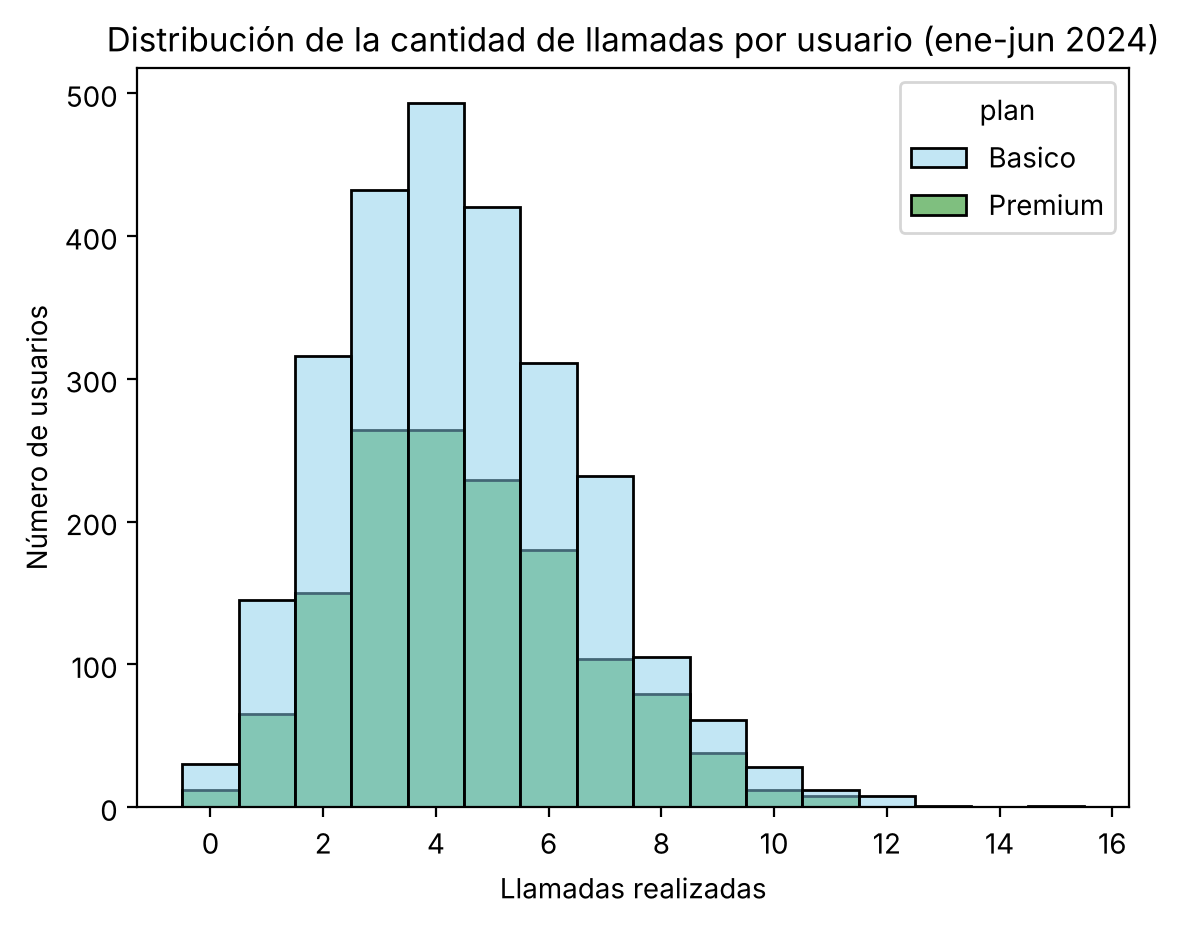

In [34]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de la cantidad de llamadas por usuario (ene-jun 2024)')
plt.xlabel('Llamadas realizadas')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights:
- Distribución **ligeramente sesgada a la derecha**: la mitad de los usuarios hizo entre 3 y 6 llamadas en el semestre, con un centro en 4, y unos pocos llegan hasta 15.
- Los usuarios Basico y Premium hacen prácticamente las mismas llamadas (4.5 en promedio, ver la sección 6.4): no existe un patrón por plan.

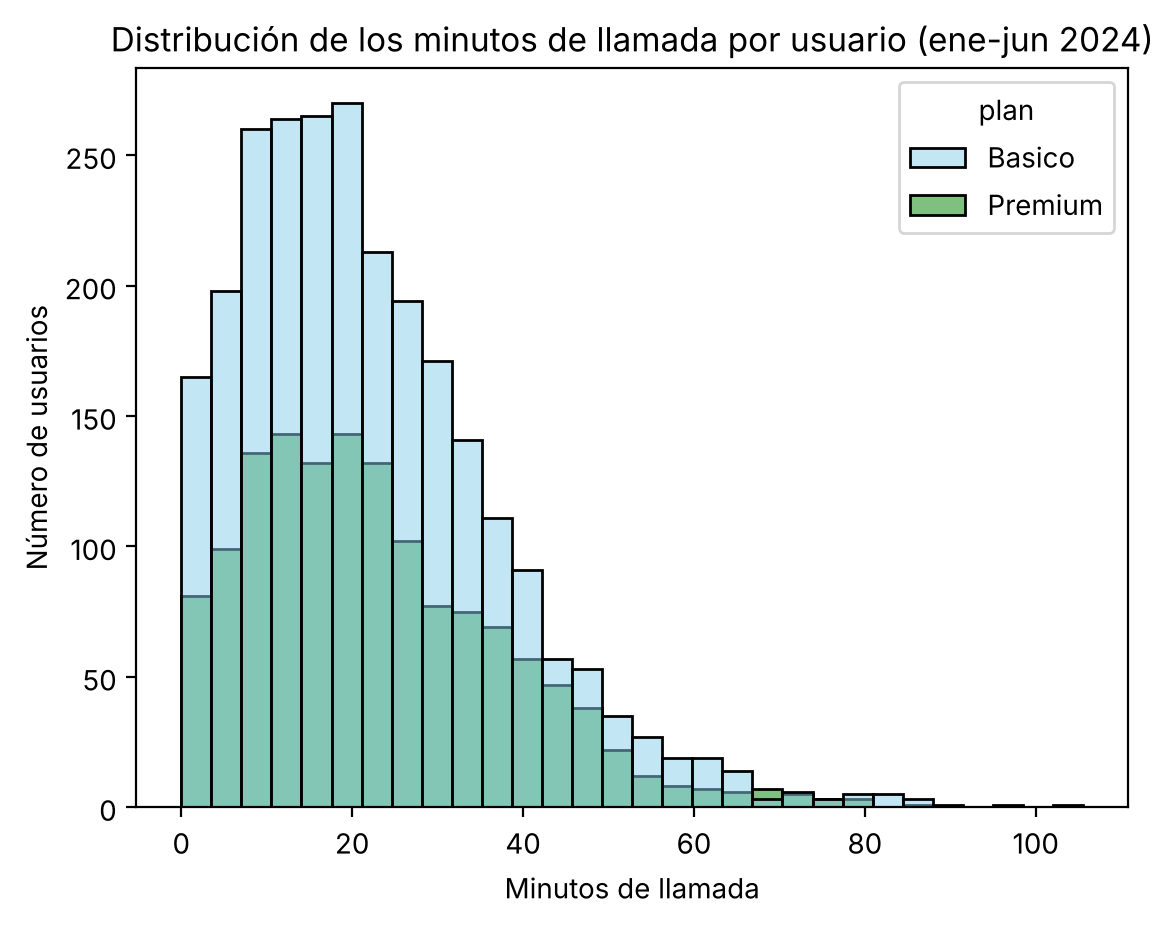

In [35]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], bins=30)
plt.title('Distribución de los minutos de llamada por usuario (ene-jun 2024)')
plt.xlabel('Minutos de llamada')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights:
- Distribución **sesgada a la derecha**: la mitad de los usuarios habló entre 11 y 31 minutos en el semestre (mediana de 19.7), pero hay una cola larga que llega hasta 105.5 minutos. Por eso la media (22.4) es mayor que la mediana.
- Los usuarios Premium hablan apenas un poco más que los Basico (22.9 contra 22.2 minutos en promedio, ver la sección 6.4). La diferencia es muy pequeña: no hay un patrón claro por plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

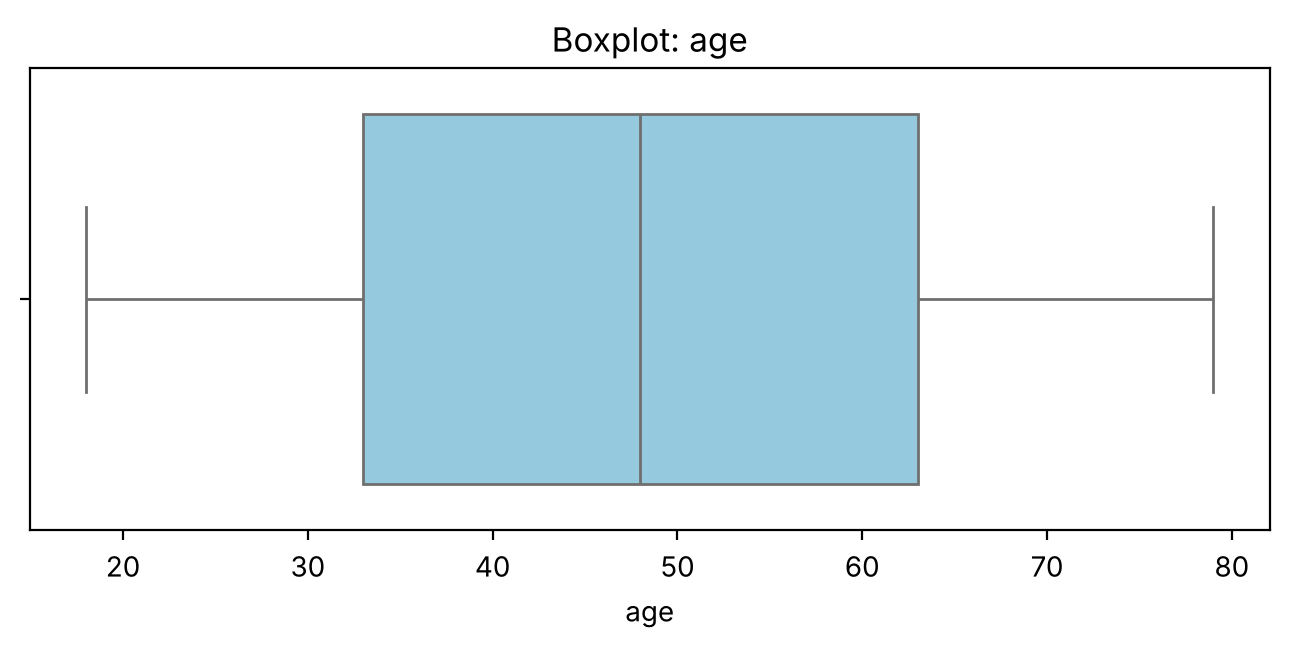

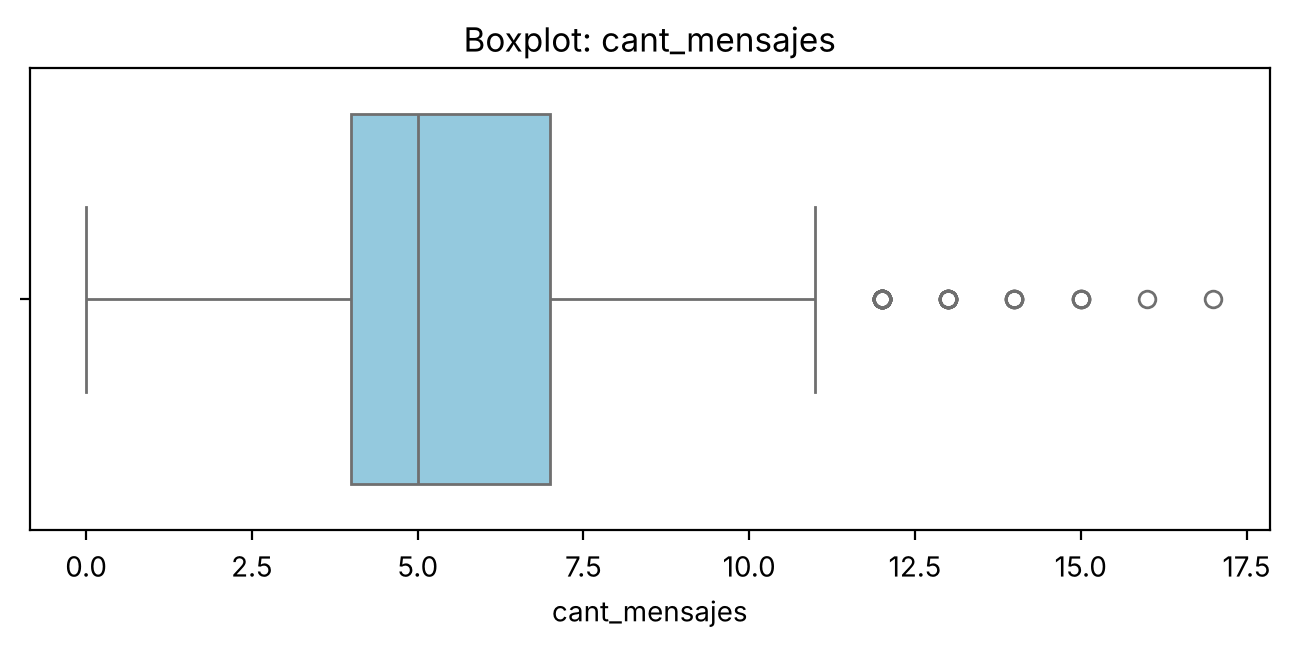

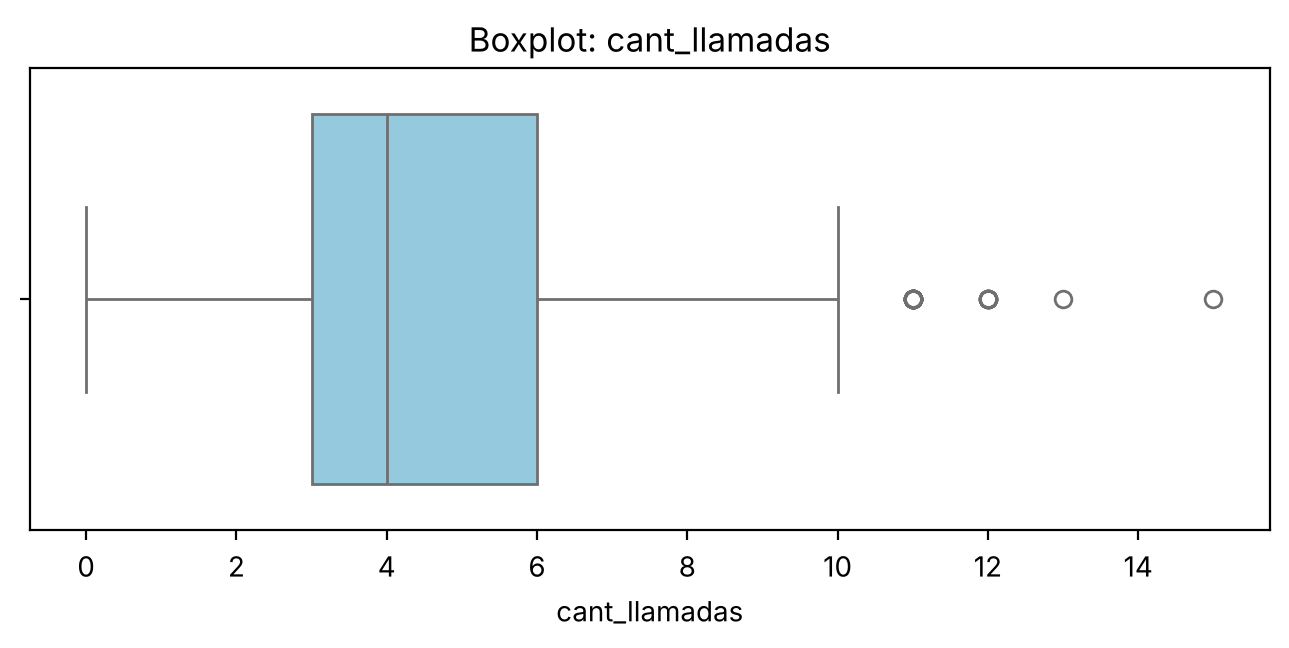

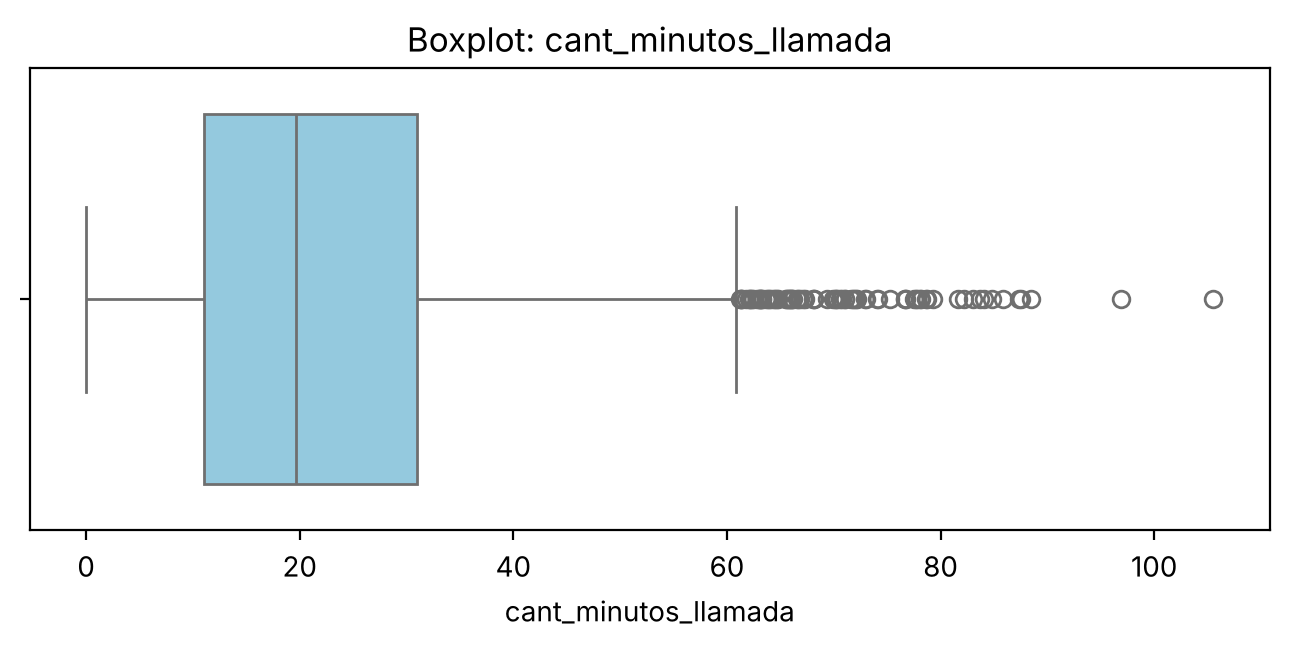

In [36]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- Age: **no presenta outliers**; todas las edades, de 18 a 79 años, quedan dentro de los bigotes.
- cant_mensajes: **presenta outliers** del lado derecho: usuarios con muchos más mensajes que el resto.
- cant_llamadas: **presenta outliers** del lado derecho.
- cant_minutos_llamada: **presenta outliers** del lado derecho; es la variable con la cola más larga.

In [37]:
# Calcular límites con el método IQR
# los outliers solo aparecen del lado derecho, así que basta con el límite superior
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}, límite superior = {limite_superior:.2f}, "
          f"usuarios por encima = {n_outliers}")

cant_mensajes: Q1 = 4.0, Q3 = 7.0, IQR = 3.0, límite superior = 11.50, usuarios por encima = 46
cant_llamadas: Q1 = 3.0, Q3 = 6.0, IQR = 3.0, límite superior = 10.50, usuarios por encima = 30
cant_minutos_llamada: Q1 = 11.08, Q3 = 30.9925, IQR = 19.9125, límite superior = 60.86, usuarios por encima = 84


In [38]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.411225
std,2.359738,2.145139,15.053351
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.080000
50%,5.000000,4.000000,19.670000
75%,7.000000,6.000000,30.992500
max,17.000000,15.000000,105.540000


💡Insights:
- cant_mensajes: **mantener los outliers.** Son 46 usuarios con más de 11.5 mensajes en el semestre (el máximo es 17). Son valores posibles, no errores: representan a los clientes que más usan el servicio, un grupo que interesa al negocio.
- cant_llamadas: **mantener los outliers.** Son 30 usuarios con más de 10.5 llamadas (el máximo es 15), una cantidad razonable para seis meses.
- cant_minutos_llamada: **mantener los outliers.** Son 84 usuarios con más de 60.86 minutos (el máximo es 105.5). Después de quitar el sentinel de 120, ninguna llamada supera los 47 minutos, así que estos totales vienen de clientes que llaman más seguido o por más tiempo, no de errores de captura.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [39]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'Bajo uso',
    np.where((user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'Uso medio',
             'Alto uso')
)

In [40]:
# verificar cambios
print(user_profile['grupo_uso'].value_counts())
print((user_profile['grupo_uso'].value_counts(normalize=True) * 100).round(1))
user_profile.head()

grupo_uso
Uso medio    2943
Bajo uso      779
Alto uso      278
Name: count, dtype: int64
grupo_uso
Uso medio    73.6
Bajo uso     19.5
Alto uso      7.0
Name: proportion, dtype: float64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [41]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30, 'Joven',
    np.where(user_profile['age'] < 60, 'Adulto', 'Adulto Mayor')
)

In [42]:
# verificar cambios
print(user_profile['grupo_edad'].value_counts())
print((user_profile['grupo_edad'].value_counts(normalize=True) * 100).round(1))
user_profile.head()

grupo_edad
Adulto          2018
Adulto Mayor    1222
Joven            760
Name: count, dtype: int64
grupo_edad
Adulto          50.4
Adulto Mayor    30.6
Joven           19.0
Name: proportion, dtype: float64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

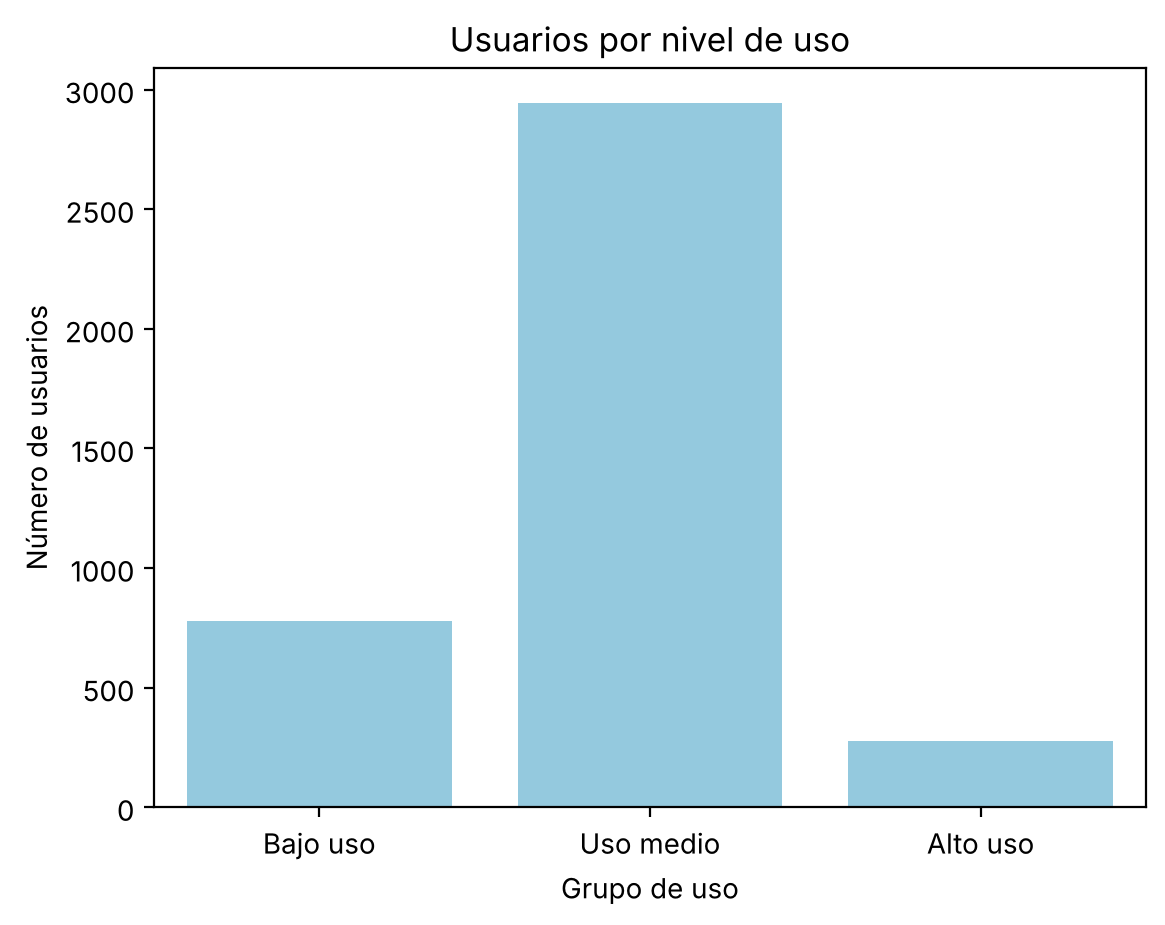

In [43]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'],
              color='skyblue')
plt.title('Usuarios por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Número de usuarios')
plt.show()

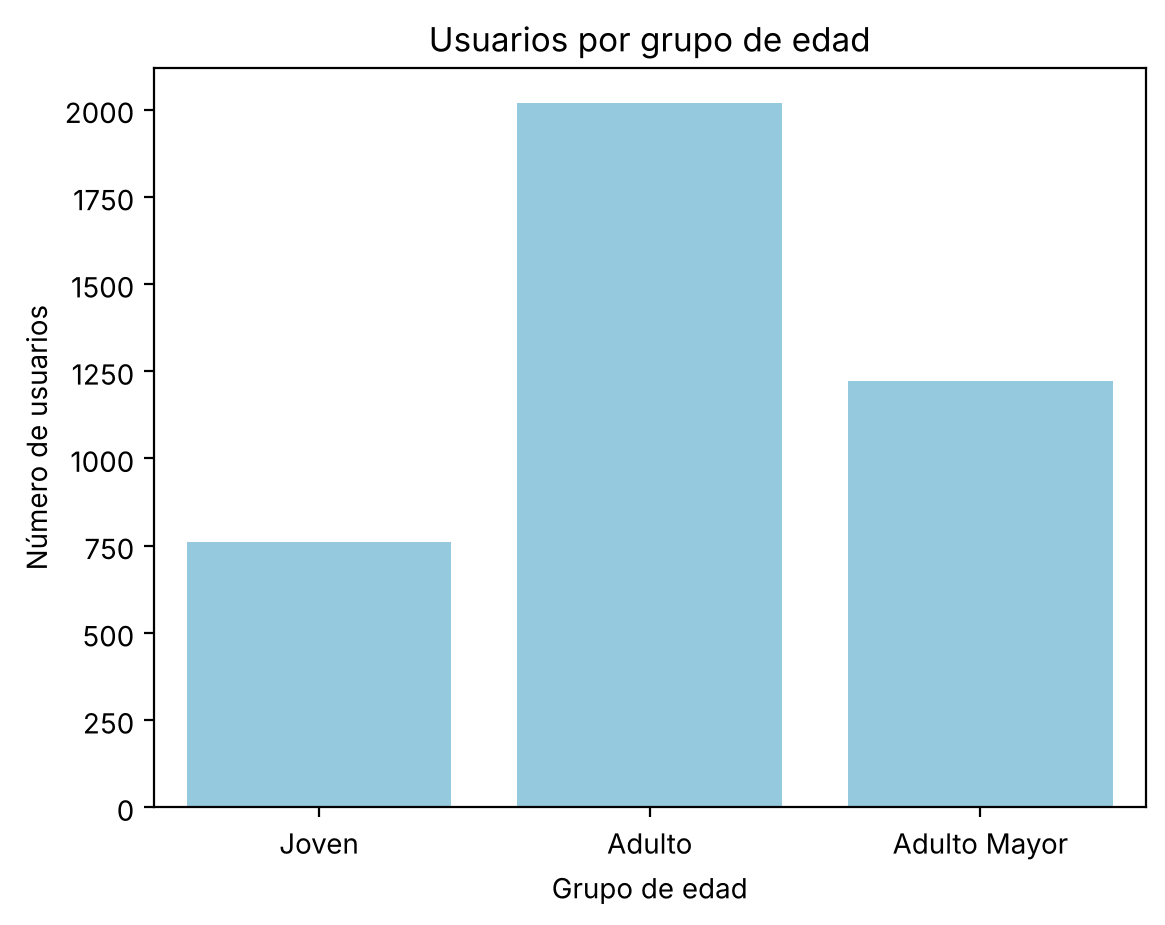

In [44]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'],
              color='skyblue')
plt.title('Usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Número de usuarios')
plt.show()

### 6.4 (Adicional) Uso por plan, edad y país

Para responder cómo varía el uso según la edad y el tipo de plan, se comparan los promedios de cada segmento. También se agrega el país (a partir de la ciudad) y se compara el uso mensual con lo que incluye cada plan.

In [45]:
# Uso promedio por plan
columnas_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print("Uso promedio por plan (ene-jun 2024)")
print(user_profile.groupby('plan')[columnas_uso].mean().round(2))

# Uso promedio por grupo de edad
print("\nUso promedio por grupo de edad")
print(user_profile.groupby('grupo_edad')[columnas_uso].mean().round(2))

# Uso promedio por país (las ciudades de México y Colombia)
pais_por_ciudad = {'CDMX': 'México', 'GDL': 'México', 'MTY': 'México',
                   'Bogotá': 'Colombia', 'Medellín': 'Colombia', 'Cali': 'Colombia'}
user_profile['pais'] = user_profile['city'].map(pais_por_ciudad)
print("\nUso promedio por país")
print(user_profile.groupby('pais')[columnas_uso].mean().round(2))

# Distribución de los grupos de uso dentro de cada plan (%)
print("\nGrupos de uso dentro de cada plan (%)")
print((pd.crosstab(user_profile['grupo_uso'], user_profile['plan'], normalize='columns') * 100).round(1))

# Uso mensual promedio comparado con lo que incluye cada plan
meses = usage['date'].dt.to_period('M').nunique()
uso_mensual = (user_profile.groupby('plan')[['cant_mensajes', 'cant_minutos_llamada']].mean() / meses).round(2)
print(f"\nUso mensual promedio por usuario ({meses} meses registrados)")
print(uso_mensual)
print("\nLo que incluye cada plan al mes")
print(plans[['plan_name', 'messages_included', 'minutes_included', 'usd_monthly_pay']])

Uso promedio por plan (ene-jun 2024)
         cant_mensajes  cant_llamadas  cant_minutos_llamada
plan                                                       
Basico            5.53           4.45                 22.16
Premium           5.52           4.52                 22.88

Uso promedio por grupo de edad
              cant_mensajes  cant_llamadas  cant_minutos_llamada
grupo_edad                                                      
Adulto                 5.55           4.48                 22.57
Adulto Mayor           5.49           4.50                 22.10
Joven                  5.52           4.43                 22.49

Uso promedio por país


          cant_mensajes  cant_llamadas  cant_minutos_llamada
pais                                                        
Colombia           5.54           4.50                 22.65
México             5.48           4.45                 22.28

Grupos de uso dentro de cada plan (%)
plan       Basico  Premium
grupo_uso                 
Alto uso      7.1      6.6
Bajo uso     19.8     18.9
Uso medio    73.1     74.4



Uso mensual promedio por usuario (6 meses registrados)
         cant_mensajes  cant_minutos_llamada
plan                                        
Basico            0.92                  3.69
Premium           0.92                  3.81

Lo que incluye cada plan al mes
  plan_name  messages_included  minutes_included  usd_monthly_pay
0    Basico                100               100               12
1   Premium                500               600               25


💡Insights:
- El uso es **prácticamente igual en todos los segmentos**: cada usuario envía unos 5.5 mensajes y hace unas 4.5 llamadas (unos 22 minutos) en el semestre, sin importar su plan, su grupo de edad o su país.
- Los grupos de uso se reparten casi igual en los dos planes: en Basico y en Premium, alrededor de 3 de cada 4 usuarios son de uso medio, 1 de cada 5 de uso bajo y 7% de uso alto.
- En promedio, un usuario envía **menos de 1 mensaje y habla menos de 4 minutos al mes**, muy lejos de lo que incluye su plan: 100 mensajes y 100 minutos en Basico, y 500 mensajes y 600 minutos en Premium.


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- `age`: 55 registros con el sentinel -999 (1.4% de los usuarios), reemplazados por la mediana de las edades válidas (48 años).
- `city`: 96 registros con `"?"` (2.4%) más 469 nulos (11.7%). En total, 565 usuarios (14.1%) no tienen ciudad conocida.
- `reg_date`: 40 fechas de registro en 2026 (1.0%), un año que todavía no ocurría; se marcaron como nulas.
- `usage`: 30 duraciones de exactamente 120 minutos y 30 longitudes de exactamente 1490 caracteres que no eran mediciones reales (0.08% de los registros cada una); se convirtieron en nulos. Además, 50 fechas vacías (0.1%).
- `churn_date`: 466 de los 4,000 usuarios tienen fecha de baja, pero viene en notación científica y perdió precisión, así que no se pudo usar para analizar las bajas.


🔍 **Segmentos por Edad**
- Adulto (30 a 59 años): 2,018 usuarios (50.4%); Adulto Mayor (60 años o más): 1,222 (30.6%); Joven (menos de 30): 760 (19.0%).
- Los tres grupos usan el servicio casi igual: alrededor de 5.5 mensajes, 4.5 llamadas y 22 minutos por usuario en el semestre. Además, cada grupo pesa lo mismo en Basico que en Premium. La edad no cambia el patrón de uso.


📊 **Segmentos por Nivel de Uso**
- Uso medio: 2,943 usuarios (73.6%); Bajo uso: 779 (19.5%); Alto uso: 278 (7.0%).
- Los grupos de uso se reparten casi igual en los dos planes: los clientes Premium no hacen más llamadas ni envían más mensajes que los Basico.
- Los outliers de uso (46 usuarios en mensajes, 30 en llamadas y 84 en minutos) son clientes intensivos reales, no errores de captura, así que se conservaron.


➡️ **Esto sugiere que...**
- **Hecho:** el uso de llamadas y mensajes es bajo y homogéneo. En promedio, cada usuario envía menos de 1 mensaje y habla menos de 4 minutos al mes, sin diferencias por edad, plan ni país. Ningún usuario se acerca a lo que incluye el plan Basico (100 mensajes y 100 minutos al mes).
- **Interpretación:** los clientes Premium pagan más del doble (25 contra 12 USD al mes) por minutos y mensajes que no usan. La diferencia entre los planes no está en las llamadas ni en los mensajes.
- **Hipótesis (por validar):** el valor que buscan los clientes Premium podría estar en los datos móviles (GB), que no vienen en `usage`, o el registro de uso podría estar incompleto. Ninguna de las dos se puede comprobar con estos datos.


💡 **Recomendaciones**
- **Revisar el diseño de los planes:** con este nivel de uso, los minutos y mensajes incluidos están sobredimensionados. Conviene diferenciar Premium por beneficios que sí se usen, como más datos, en lugar de más minutos y mensajes.
- **Crear un plan ligero para el 19.5% de bajo uso:** un plan más barato, con menos minutos y mensajes, podría retener a estos clientes antes de que se den de baja.
- **Proteger a los clientes Premium (35%):** son los que más podrían notar que pagan por capacidad que no usan y bajarse a Basico o irse. Un ajuste de beneficios o de precio puede evitarlo.
- **Ofrecer al 7% de alto uso beneficios distintos a más minutos:** incluso ellos caben en el plan Basico, así que una invitación a Premium tendría que basarse en otros beneficios.
- **Corregir la captura de datos:** recuperar `churn_date` en formato de fecha, completar las ciudades faltantes y revisar el sistema que genera los valores 120 y 1490.
- **Siguiente análisis:** sumar el consumo de datos (GB) y los cargos extra para confirmar dónde está el valor de cada plan, y analizar las bajas cuando `churn_date` esté corregida.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

In [ ]:
https://github.com/Nangris/ConnectaTel